In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/ecommerce_customer_behavior_dataset.csv")

In [3]:
df.tail(2)

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
4998,ORD_004443,CUST_04443,2024-03-26,41,Female,Istanbul,Fashion,171.19,1,0.00,171.19,Credit Card,Mobile,20,12,True,5,4
4999,ORD_000902,CUST_00902,2024-03-26,30,Female,Konya,Books,84.30,4,21.72,315.48,Debit Card,Desktop,8,9,True,5,5


# Lets take only numeric value for statistical analysis.

In [5]:
numeric_df=df[['Age','Unit_Price','Quantity','Discount_Amount','Total_Amount','Session_Duration_Minutes','Pages_Viewed','Delivery_Time_Days','Customer_Rating']]

# Mean for all values

In [6]:
numeric_df.mean()

,0
Age,35.032600
Unit_Price,455.834120
Quantity,2.220000
Discount_Amount,24.852804
Total_Amount,983.108914
Session_Duration_Minutes,14.573400
Pages_Viewed,8.984200
Delivery_Time_Days,6.497000
Customer_Rating,3.902800


Median for all values

In [7]:
numeric_df.median()

,0
Age,35.00
Unit_Price,182.95
Quantity,2.00
Discount_Amount,0.00
Total_Amount,337.91
Session_Duration_Minutes,13.00
Pages_Viewed,9.00
Delivery_Time_Days,6.00
Customer_Rating,4.00


Mode for all values

In [8]:
numeric_df.mode()

,Age,Unit_Price,Quantity,Discount_Amount,Total_Amount,Session_Duration_Minutes,Pages_Viewed,Delivery_Time_Days,Customer_Rating
0,18.0,30.1,1.0,0.0,23.05,9.0,8.0,5.0,5.0
1,NaN,NaN,NaN,NaN,82.08,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,114.30,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,167.26,NaN,NaN,NaN,NaN


# Variance for all values(population variance)

In [13]:
numeric_df.var(ddof=0)

,0
Age,1.227539e+02
Unit_Price,5.075222e+05
Quantity,1.956000e+00
Discount_Amount,7.810368e+03
Total_Amount,3.605398e+06
Session_Duration_Minutes,7.508021e+01
Pages_Viewed,7.862750e+00
Delivery_Time_Days,1.200359e+01
Customer_Rating,1.273352e+00


# standard deviation for all numeric values

In [10]:
numeric_df.std()

,0
Age,11.080546
Unit_Price,712.477209
Quantity,1.398711
Discount_Amount,88.385124
Total_Amount,1898.978528
Session_Duration_Minutes,8.665750
Pages_Viewed,2.804340
Delivery_Time_Days,3.464966
Customer_Rating,1.128542


# To find all at once we use describe function

In [14]:
numeric_df.describe()

,Age,Unit_Price,Quantity,Discount_Amount,Total_Amount,Session_Duration_Minutes,Pages_Viewed,Delivery_Time_Days,Customer_Rating
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.00000,5000.000000,5000.000000
mean,35.032600,455.834120,2.220000,24.852804,983.108914,14.57340,8.98420,6.497000,3.902800
std,11.080546,712.477209,1.398711,88.385124,1898.978528,8.66575,2.80434,3.464966,1.128542
min,18.000000,5.180000,1.000000,0.000000,7.870000,1.00000,1.00000,1.000000,1.000000
25%,27.000000,76.587500,1.000000,0.000000,122.517500,8.00000,7.00000,4.000000,3.000000
50%,35.000000,182.950000,2.000000,0.000000,337.910000,13.00000,9.00000,6.000000,4.000000
75%,42.000000,513.930000,3.000000,8.760000,979.695000,19.00000,11.00000,8.000000,5.000000
max,75.000000,7159.450000,5.000000,1525.550000,22023.900000,73.00000,24.00000,25.000000,5.000000


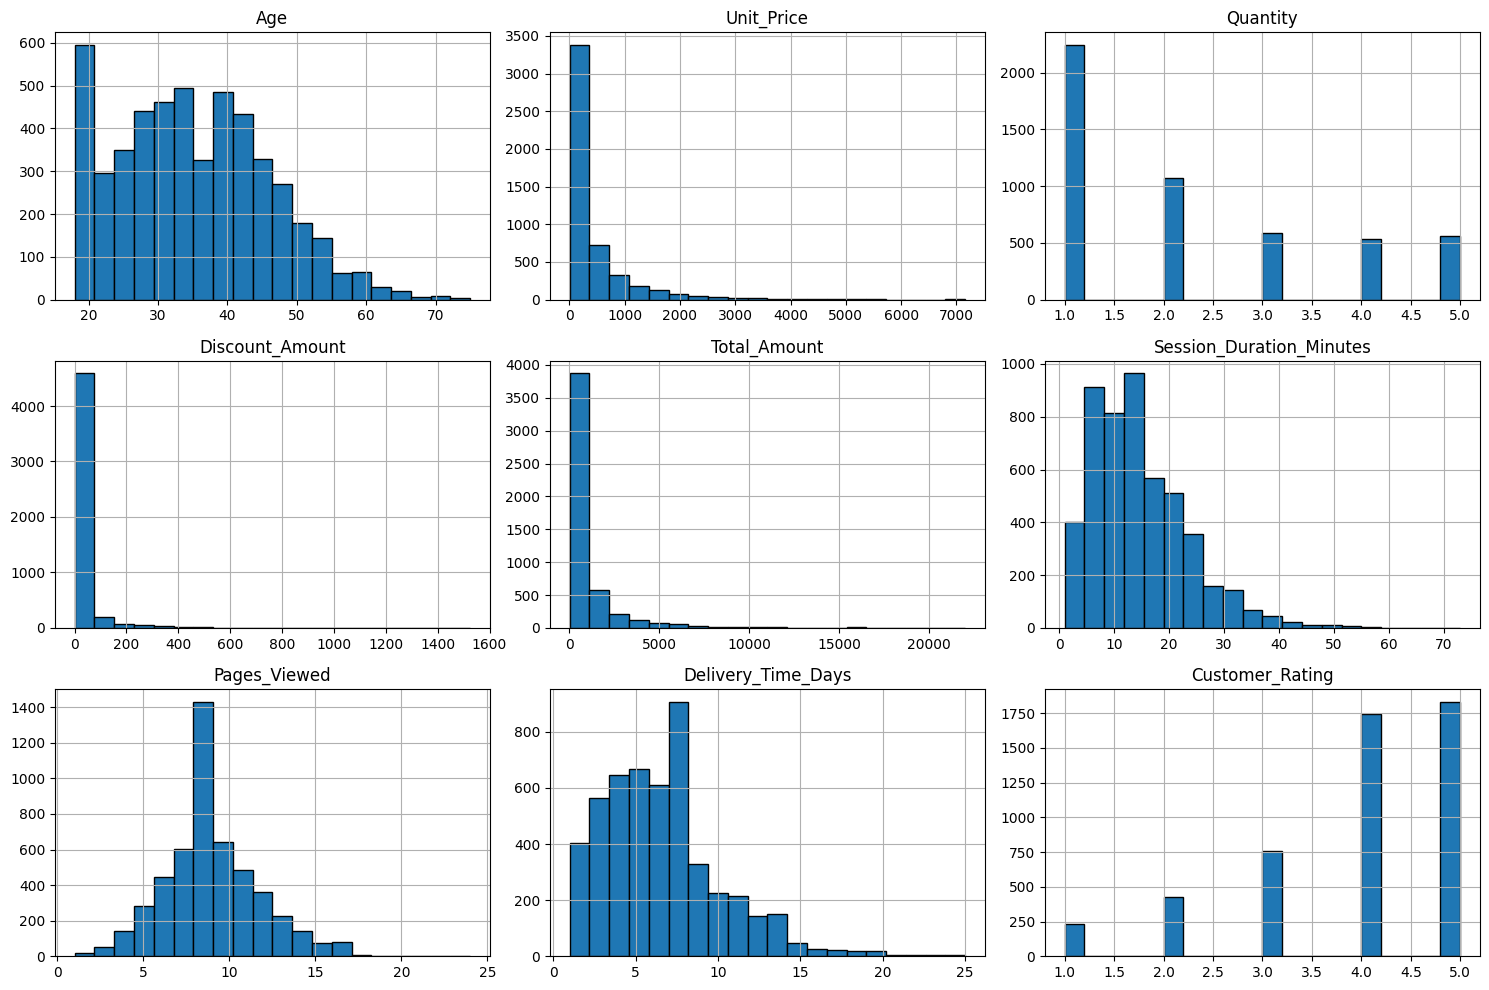

In [17]:
numeric_df.hist(figsize=(15, 10), bins=20, edgecolor='black')

plt.tight_layout()
plt.show()

In [20]:
def classify_distribution(skewness):
    if -0.5 <= skewness <= 0.5:
        return 'Approximately Normal'
    elif skewness > 0.5:
        return 'Right Skewed'
    else:
        return 'Left Skewed'

distribution = numeric_df.skew().apply(classify_distribution)

result = pd.DataFrame({
    'Column_name': numeric_df.columns,
    'Skewness': numeric_df.skew().values,
    'Distribution': distribution.values
})

print(result)

                Column_name  Skewness          Distribution
0                       Age  0.335670  Approximately Normal
1                Unit_Price  3.471454          Right Skewed
2                  Quantity  0.824779          Right Skewed
3           Discount_Amount  7.401594          Right Skewed
4              Total_Amount  4.895841          Right Skewed
5  Session_Duration_Minutes  1.160301          Right Skewed
6              Pages_Viewed  0.371004  Approximately Normal
7        Delivery_Time_Days  1.110639          Right Skewed
8           Customer_Rating -0.948843           Left Skewed


# The age and Pages_viewed columns follows normal distbution, rest are left and right skewed.

# Comparsion of distribution using box plots


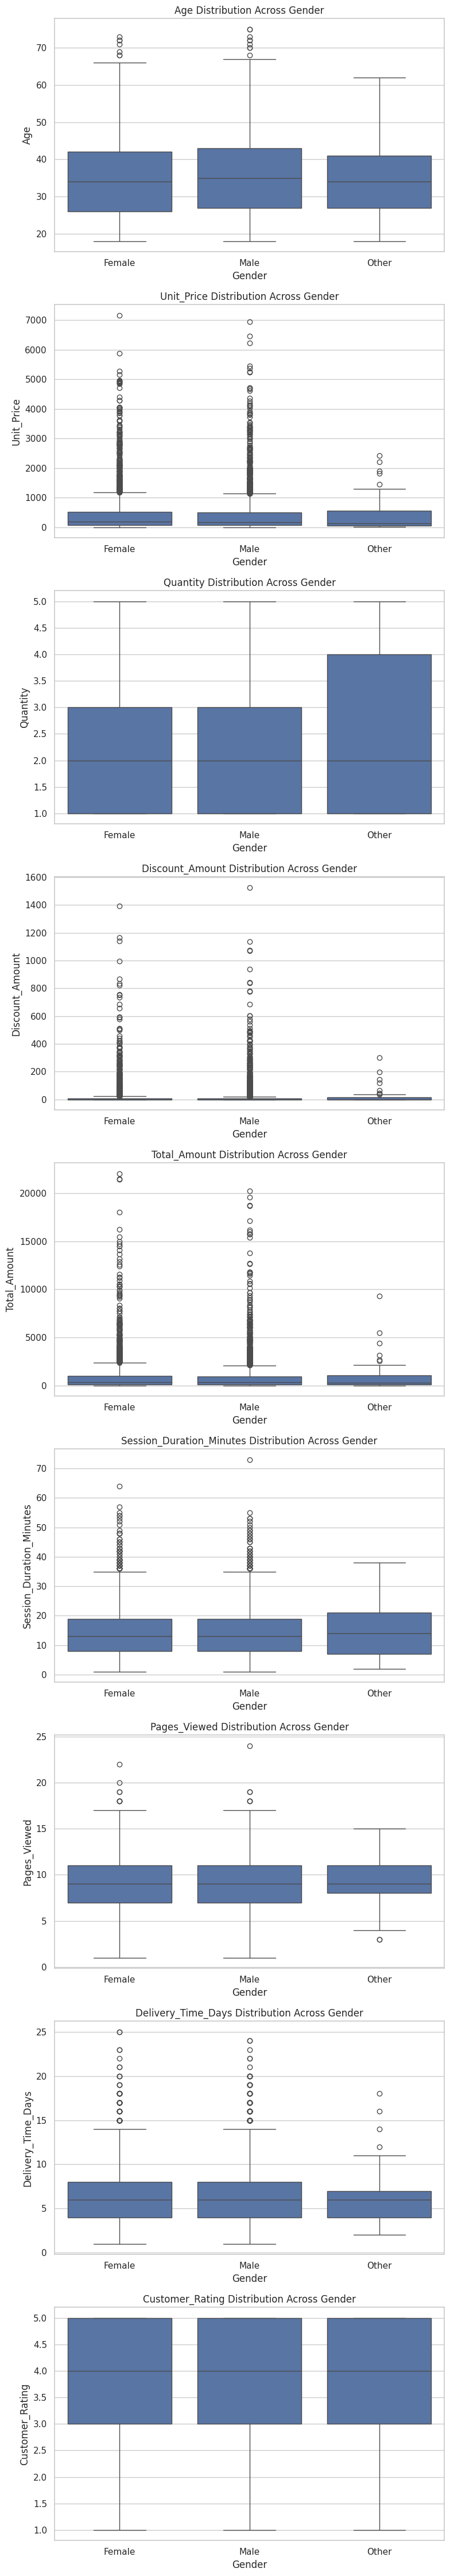

In [23]:
numeric_cols = numeric_df.columns

fig, axes = plt.subplots(
    nrows=len(numeric_cols),
    ncols=1,
    figsize=(8, 5 * len(numeric_cols))
)

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='Gender', y=col, ax=axes[i])
    axes[i].set_title(f'{col} Distribution Across Gender')

plt.tight_layout()
plt.show()